# Taller C3 · Stacking aplicado a Yomi Level
**Aprendizaje Supervisado · Universidad Sergio Arboleda**
José Santiago González · Oscar Mateo Arrubla · Leonardo Diasgranados · Docente: Hernán Cruz Bueno

**Sector:** aprendizaje de japonés con contenido audiovisual (anime, doramas y cine japonés).
**Tarea:** clasificación. Predecir si el japonés de un título será **Fácil, Intermedio o Difícil** para un estudiante.

**La idea del taller:** en Voting, los 3 modelos votan y todos los votos valen lo mismo (una *democracia*). En **Stacking** agregamos un **meta-modelo**, un "juez", que **aprende a quién creerle** según el caso (una *meritocracia*). El juez no ve los datos del título: solo ve lo que dicen los 3 expertos.

```
Datos del título (28 variables)
        │
        ├──► KNN ─────────────┐
        ├──► SVM ─────────────┼──► probabilidades ──► META-MODELO (Regresión Logística) ──► Fácil / Intermedio / Difícil
        └──► Random Forest ───┘        (nivel 0)                     (nivel 1)
```

In [1]:
# ============================================================
# Librerías y estilo de las gráficas
# ============================================================
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score, roc_auc_score,
                             confusion_matrix, classification_report)
warnings.filterwarnings('ignore')
os.makedirs('figuras', exist_ok=True)
sns.set_theme(style='whitegrid', font_scale=0.95)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
ORDEN = ['Fácil', 'Intermedio', 'Difícil']
COLOR = {'KNN': '#9AA3AD', 'SVM': '#7C93B0', 'Random Forest': '#2B4A6F',
         'Voting Soft': '#F2A900', 'Stacking': '#D9480F'}

## 1 · El dataset

| Aspecto | Detalle |
|---|---|
| Fuente | Moe-DB + AniList + TMDB: 9.977 títulos; quedan **9.034** tras quitar los que no tienen metadatos |
| Variables | **28**: palabras por episodio, palabras distintas y episodios (en logaritmo), año, anime/live-action, película/serie, género desconocido y 21 géneros |
| Objetivo | Dificultad (1-100) en terciles: **Fácil** < 19,9 · **Intermedio** 19,9-25,4 · **Difícil** > 25,4 |
| Tipo | **Clasificación multiclase** (3 clases balanceadas; el azar acierta 33%) |
| División | 80/20 estratificada, semilla 42: 7.227 de entrenamiento y 1.807 de prueba (la misma de todos los talleres) |

**¿Por qué clasificación y no regresión?** La app decide por niveles (semáforo verde, amarillo y rojo), y así podemos comparar directamente con los modelos y el Voting de los talleres anteriores.

In [2]:
# ============================================================
# 1 · Cargar y preparar el dataset (mismo preprocesamiento de todos los talleres)
# ============================================================
# El CSV se lee junto al notebook; en Colab, si no se subió, se descarga del repositorio
ruta = ('moe_db_anilist_dataset.csv' if os.path.exists('moe_db_anilist_dataset.csv')
        else 'https://raw.githubusercontent.com/JoSker51/TallerC3_2/main/moe_db_anilist_dataset.csv')
df = pd.read_csv(ruta)
df = df[df['entry_type'].notna()].copy()                      # quitamos títulos sin metadatos

# Objetivo: dificultad (1-100) en terciles -> 3 clases del mismo tamaño
df['nivel'], cortes = pd.qcut(df['Overall Difficulty (1-100)'], 3, labels=ORDEN, retbins=True)

# Faltantes con la mediana de su mismo formato; formato y géneros como columnas 0/1
for c in ['episodes', 'start_year']:
    df[c] = df[c].fillna(df.groupby('entry_type')[c].transform('median'))
df['genero_desconocido'] = df['genres'].isna().astype(int)
df['es_anime'] = df['entry_type'].str.startswith('anime').astype(int)
df['es_pelicula'] = df['entry_type'].str.endswith('movie').astype(int)
g = (df['genres'].fillna('')
     .str.replace('Sci-Fi & Fantasy', 'Sci-Fi, Fantasy', regex=False)
     .str.replace('Action & Adventure', 'Action, Adventure', regex=False)
     .str.replace('War & Politics', 'War', regex=False)
     .str.replace('Science Fiction', 'Sci-Fi', regex=False))
gen = g.str.get_dummies(sep=', ')
gen = gen.loc[:, gen.sum() >= 100]
gen.columns = ['g_' + c for c in gen.columns]
df = pd.concat([df, gen], axis=1)
for c in ['Avg. Words/Episode', 'Unique Words', 'episodes']:
    df['log_' + c] = np.log1p(df[c])

# 28 variables. Sin Kanji/Vocab Difficulty ni Vocab Density: la etiqueta se calcula con ellas (fuga de datos)
features = (['log_Avg. Words/Episode', 'log_Unique Words', 'log_episodes', 'start_year',
             'es_anime', 'es_pelicula', 'genero_desconocido'] + list(gen.columns))
X, y = df[features], df['nivel'].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Títulos: {len(df):,} | variables: {len(features)} | train: {len(X_train):,} | test: {len(X_test):,}".replace(',', '.'))
print("Balance:", y.value_counts().reindex(ORDEN).to_dict(), "| cortes:", np.round(cortes[1:3], 1))

Títulos: 9.034 | variables: 28 | train: 7.227 | test: 1.807
Balance: {'Fácil': 3017, 'Intermedio': 3015, 'Difícil': 3002} | cortes: [19.9 25.4]


## 2 · Modelos base (nivel 0)

Como indica la clase: *"cada modelo base mantiene sus propios hiperparámetros tal como en los ejercicios individuales"*. Usamos los 3 modelos de nuestros talleres, de **familias distintas**, que es la "regla de oro" del stacking (no tres árboles iguales):

| Experto | Familia | Parámetros (de cada taller) | En qué se equivoca |
|---|---|---|---|
| **KNN** | Distancias | K=39, Manhattan, pesos por distancia | Cuando no hay títulos parecidos cerca |
| **SVM** | Márgenes | Kernel RBF, C=100, gamma='scale' | Cuando la frontera entre niveles es muy irregular |
| **Random Forest** | Árboles | 300 árboles, profundidad 15, 40% de variables | Con valores fuera de lo que vio al entrenar |

In [3]:
# ============================================================
# 2 · Modelos base (nivel 0): los parámetros que encontramos en cada taller
# ============================================================
modelos_base = {
    # Taller KNN: GridSearchCV (5 folds) -> K=39, Manhattan, pesos por distancia
    'KNN': make_pipeline(StandardScaler(),
                         KNeighborsClassifier(n_neighbors=39, metric='manhattan', weights='distance')),
    # Taller SVM: GridSearch de 20 combinaciones -> RBF, C=100, gamma='scale'
    'SVM': make_pipeline(StandardScaler(),
                         SVC(kernel='rbf', C=100, gamma='scale', probability=True, random_state=42)),
    # Proyecto final: 300 árboles, profundidad 15, 40% de variables por división
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=15, max_features=0.4,
                                            random_state=42, n_jobs=-1),
}

def errores_graves(real, pred):
    """% de títulos donde se confunde un extremo con el otro (Fácil <-> Difícil)."""
    real, pred = np.asarray(real), np.asarray(pred)
    return np.mean(((real == 'Fácil') & (pred == 'Difícil')) | ((real == 'Difícil') & (pred == 'Fácil')))

def evaluar(modelo):
    pred = modelo.predict(X_test)
    proba = modelo.predict_proba(X_test)[:, [list(modelo.classes_).index(c) for c in ORDEN]]
    return pred, {'Accuracy': accuracy_score(y_test, pred),
                  'F1-macro': f1_score(y_test, pred, average='macro'),
                  'AUC': roc_auc_score(label_binarize(y_test, classes=ORDEN), proba, average='macro'),
                  'Recall Difícil': recall_score(y_test, pred, labels=['Difícil'], average='macro'),
                  'Errores graves': errores_graves(y_test, pred)}

pred, tabla = {}, {}
for nombre, modelo in modelos_base.items():
    modelo.fit(X_train, y_train)
    pred[nombre], tabla[nombre] = evaluar(modelo)
pd.DataFrame(tabla).T.round(3)

,Accuracy,F1-macro,AUC,Recall Difícil,Errores graves
KNN,0.546,0.544,0.737,0.602,0.079
SVM,0.570,0.568,0.746,0.662,0.065
Random Forest,0.581,0.580,0.770,0.650,0.061


## 3 · Stacking: el meta-modelo

- **Meta-modelo:** `LogisticRegression`. Un "jefe simple y con criterio", como recomienda la clase: los modelos base ya hicieron el trabajo pesado y un juez complejo se sobreajustaría.
- **cv=5 (out-of-fold):** el juez aprende con predicciones que cada experto hizo sobre títulos que **no vio** al entrenar. Si no, el juez creería en el modelo que más memorizó (lo comprobamos en la sección 7).
- **stack_method='predict_proba':** el juez recibe **probabilidades** (9 números: 3 por experto) y no solo la etiqueta, así sabe qué tan seguro está cada uno.

También entrenamos el **Voting Soft** del taller anterior para comparar.

In [4]:
# ============================================================
# 3 · Stacking: los 3 modelos base + un meta-modelo (nivel 1) que aprende a combinarlos
# ============================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

stacking = StackingClassifier(
    estimators=list(modelos_base.items()),            # nivel 0: los "expertos"
    final_estimator=LogisticRegression(max_iter=2000), # nivel 1: el "juez", simple a propósito
    cv=cv,                                             # el juez aprende con predicciones out-of-fold
    stack_method='predict_proba',                      # le pasamos probabilidades, no solo etiquetas
    n_jobs=-1)
stacking.fit(X_train, y_train)
pred['Stacking'], tabla['Stacking'] = evaluar(stacking)

# Voting Soft del taller anterior, para comparar "democracia" contra "meritocracia"
voting = VotingClassifier(list(modelos_base.items()), voting='soft', n_jobs=-1).fit(X_train, y_train)
pred['Voting Soft'], tabla['Voting Soft'] = evaluar(voting)

orden_m = ['KNN', 'SVM', 'Random Forest', 'Voting Soft', 'Stacking']
resultados = pd.DataFrame(tabla).T.loc[orden_m]
resultados.round(3)

,Accuracy,F1-macro,AUC,Recall Difícil,Errores graves
KNN,0.546,0.544,0.737,0.602,0.079
SVM,0.570,0.568,0.746,0.662,0.065
Random Forest,0.581,0.580,0.770,0.650,0.061
Voting Soft,0.593,0.591,0.769,0.663,0.056
Stacking,0.600,0.600,0.779,0.672,0.050


In [5]:
# Reporte por clase del Stacking
print(classification_report(y_test, pred['Stacking'], labels=ORDEN, digits=3))

              precision    recall  f1-score   support

       Fácil      0.659     0.659     0.659       604
  Intermedio      0.475     0.469     0.472       603
     Difícil      0.664     0.672     0.668       600

    accuracy                          0.600      1807
   macro avg      0.599     0.600     0.600      1807
weighted avg      0.599     0.600     0.600      1807



## 4 · ¿A quién le cree el juez?

Cada casilla es el peso que el meta-modelo le da a una probabilidad de un experto cuando decide un nivel. **Rojo** = esa opinión empuja hacia ese nivel; **azul** = lo aleja.

**Lo que aprendió el juez:**
- **Le cree mucho más a Random Forest:** para decidir *Fácil* le da peso **1,73** a lo que dice Random Forest, frente a 0,77 del SVM y 0,31 de KNN. Para *Difícil*, **1,66** frente a 0,67 y 0,51.
- **El SVM es el segundo experto** en todos los niveles.
- **KNN casi no cuenta para Intermedio (0,08):** el juez aprendió que KNN no sabe distinguir ese nivel y lo ignora ahí.
- **Usa también los "no":** si Random Forest da alta probabilidad de *Fácil*, eso resta mucho para *Difícil* (**−1,31**). El juez no solo suma votos, también descarta.

Esta es la diferencia con Voting: allí los 3 pesaban igual (1/3 cada uno); aquí los pesos se **aprendieron** según quién suele acertar.

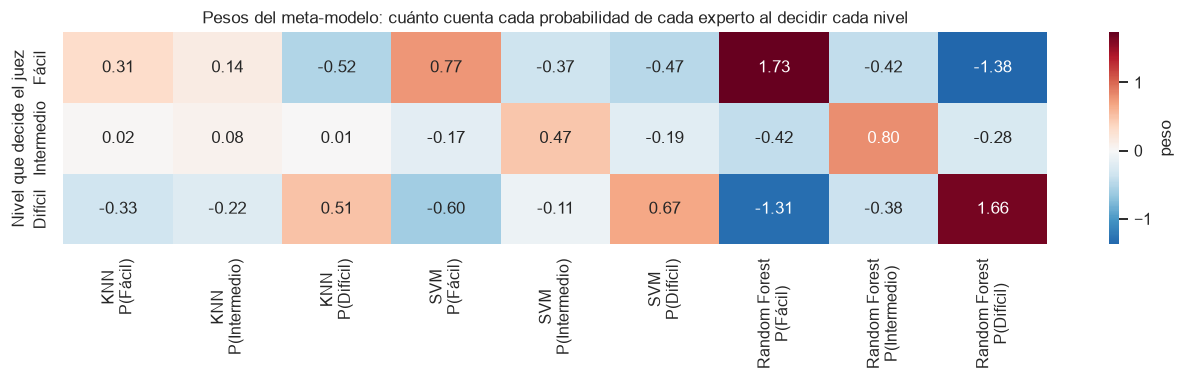

,KNN,SVM,Random Forest
Fácil,0.31,0.77,1.73
Intermedio,0.08,0.47,0.80
Difícil,0.51,0.67,1.66


In [6]:
# ============================================================
# 4 · ¿A quién le cree el juez? Pesos aprendidos por el meta-modelo
# ============================================================
meta = stacking.final_estimator_
# Dentro del stacking las clases se codifican como 0, 1, 2; stacking.classes_ traduce el número al nombre
clases_base = [stacking.classes_[i] for i in stacking.estimators_[0].classes_]  # orden de las probabilidades de nivel 0
clases_meta = list(stacking.classes_)                                           # filas de coeficientes del meta-modelo
columnas = [f"{m}\nP({c})" for m in modelos_base for c in clases_base]
pesos = pd.DataFrame(meta.coef_, index=clases_meta, columns=columnas).loc[ORDEN]
pesos = pesos[[f"{m}\nP({c})" for m in modelos_base for c in ORDEN]]   # columnas en orden Fácil, Intermedio, Difícil

fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(pesos, annot=True, fmt='.2f', cmap='RdBu_r', center=0, cbar_kws={'label': 'peso'}, ax=ax)
ax.set_title('Pesos del meta-modelo: cuánto cuenta cada probabilidad de cada experto al decidir cada nivel')
ax.set_ylabel('Nivel que decide el juez'); ax.set_xlabel('')
plt.tight_layout(); plt.savefig('figuras/3_pesos_meta.png'); plt.show()

# Peso que cada experto le da a "su propio voto" (P(clase) para decidir esa misma clase)
confianza = pd.DataFrame({m: [pesos.loc[c, f"{m}\nP({c})"] for c in ORDEN] for m in modelos_base}, index=ORDEN)
confianza.round(2)

## 5 · Resultados: modelos base vs Voting vs Stacking

| Modelo | Accuracy | F1-macro | AUC | Recall Difícil | Errores graves |
|---|---|---|---|---|---|
| KNN | 0,546 | 0,544 | 0,737 | 0,602 | 7,9% |
| SVM | 0,570 | 0,568 | 0,746 | 0,662 | 6,5% |
| Random Forest | 0,581 | 0,580 | 0,770 | 0,650 | 6,1% |
| Voting Soft | 0,593 | 0,591 | 0,769 | 0,663 | 5,6% |
| **Stacking** | **0,600** | **0,600** | **0,779** | **0,672** | **5,0%** |

**El Stacking es el mejor en las 5 métricas.** Acierta **60 de cada 100** títulos (el azar, 33), detecta el **67%** de los títulos difíciles y comete el menor número de **errores graves**:

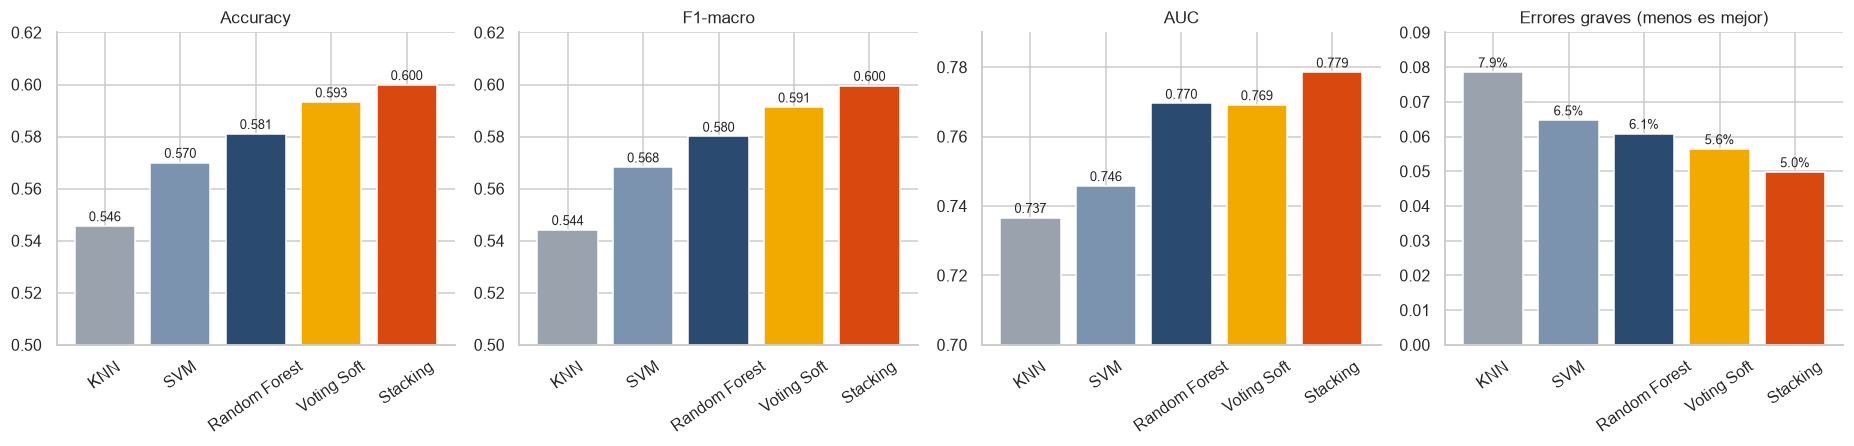

In [7]:
# ============================================================
# 5 · Comparación visual: modelos base vs Voting vs Stacking
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
lims = {'Accuracy': (0.50, 0.62), 'F1-macro': (0.50, 0.62), 'AUC': (0.70, 0.79), 'Errores graves': (0, 0.09)}
for ax, (met, lim) in zip(axes, lims.items()):
    v = resultados[met]
    barras = ax.bar(v.index, v.values, color=[COLOR[m] for m in v.index])
    for b in barras:
        txt = f"{b.get_height():.1%}" if met == 'Errores graves' else f"{b.get_height():.3f}"
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + (lim[1] - lim[0]) * 0.015, txt, ha='center', fontsize=8.5)
    ax.set_ylim(*lim); ax.set_title(met + (' (menos es mejor)' if met == 'Errores graves' else ''))
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.savefig('figuras/4_comparacion.png'); plt.show()

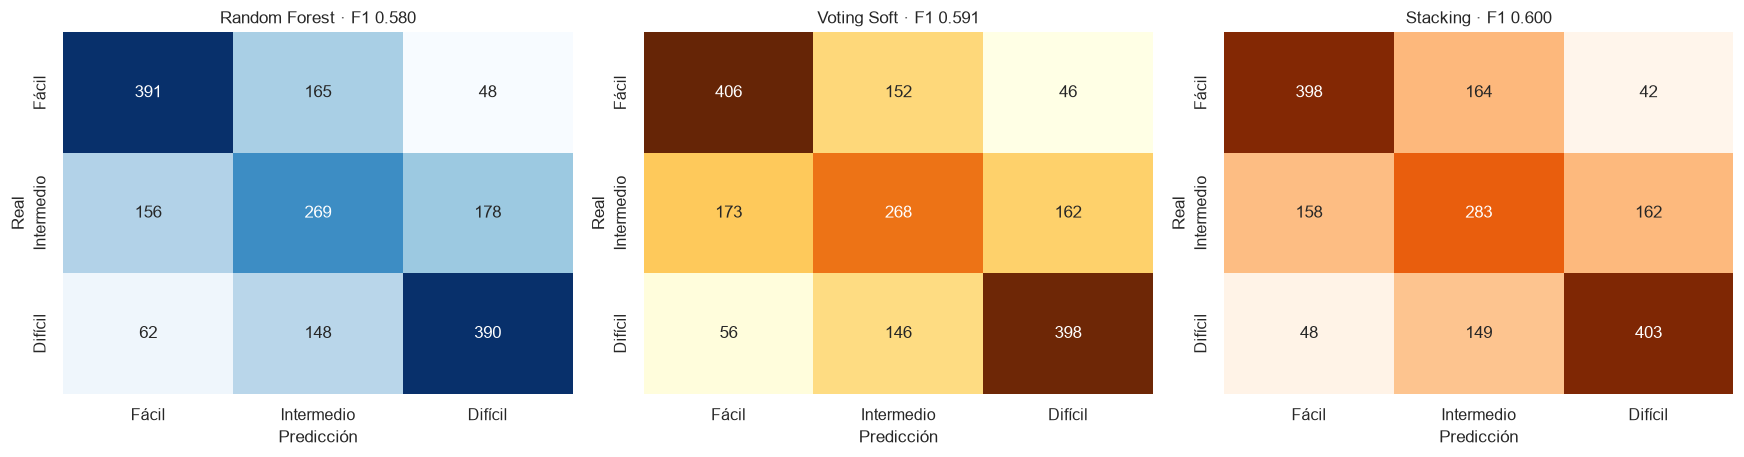

,Fácil -> Difícil,Difícil -> Fácil
KNN,58,84
SVM,62,55
Random Forest,48,62
Voting Soft,46,56
Stacking,42,48


In [8]:
# Matrices de confusión: mejor modelo solo vs Voting vs Stacking
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, nombre, cmap in zip(axes, ['Random Forest', 'Voting Soft', 'Stacking'], ['Blues', 'YlOrBr', 'Oranges']):
    cm = confusion_matrix(y_test, pred[nombre], labels=ORDEN)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False, ax=ax, xticklabels=ORDEN, yticklabels=ORDEN)
    ax.set_title(f"{nombre} · F1 {resultados.loc[nombre, 'F1-macro']:.3f}")
    ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig('figuras/5_matrices.png'); plt.show()

graves = pd.DataFrame({n: {'Fácil -> Difícil': confusion_matrix(y_test, pred[n], labels=ORDEN)[0, 2],
                           'Difícil -> Fácil': confusion_matrix(y_test, pred[n], labels=ORDEN)[2, 0]}
                       for n in orden_m}).T
graves

## 6 · ¿Qué meta-modelo elegir?

La clase sugiere probar varios "jueces". Probamos 4 opciones:

**Resultado:** las 4 quedan prácticamente empatadas (F1 entre 0,597 y 0,601). Elegimos la **Regresión Logística** por el principio de parsimonia: con el mismo resultado, el juez más simple es más estable, se entrena más rápido y sus pesos se pueden **explicar** (sección 4). El Random Forest pequeño logra un poco menos de errores graves (4,6%), pero es una caja negra y su ventaja en F1 es de solo 0,002.

- **C=0,1** hace al juez más estricto (más regularización). No mejora: no hay sobreajuste que corregir.
- **passthrough=True** le pasa al juez también los datos originales, además de las predicciones. Tampoco mejora: los expertos ya extrajeron lo útil de las 28 variables.

In [9]:
# ============================================================
# 6 · ¿Qué meta-modelo usar? Probamos 3 "jueces" y la opción passthrough
# ============================================================
candidatos = {
    'Regresión Logística (elegido)': dict(final_estimator=LogisticRegression(max_iter=2000)),
    'Regresión Logística C=0,1 (más estricta)': dict(final_estimator=LogisticRegression(C=0.1, max_iter=2000)),
    'Random Forest pequeño (profundidad 3)': dict(final_estimator=RandomForestClassifier(
        n_estimators=200, max_depth=3, random_state=42, n_jobs=-1)),
    'Regresión Logística + passthrough': dict(final_estimator=LogisticRegression(max_iter=2000), passthrough=True),
}
filas = {}
for nombre, params in candidatos.items():
    if nombre.endswith('(elegido)'):
        _, filas[nombre] = pred['Stacking'], tabla['Stacking']
        continue
    s = StackingClassifier(list(modelos_base.items()), cv=cv, n_jobs=-1, **params).fit(X_train, y_train)
    _, filas[nombre] = evaluar(s)
metas = pd.DataFrame(filas).T
metas.round(4)

,Accuracy,F1-macro,AUC,Recall Difícil,Errores graves
Regresión Logística (elegido),0.5999,0.5996,0.7785,0.6717,0.0498
"Regresión Logística C=0,1 (más estricta)",0.5977,0.5971,0.7781,0.6733,0.0504
Random Forest pequeño (profundidad 3),0.6010,0.6024,0.7767,0.6583,0.0459
Regresión Logística + passthrough,0.5988,0.5973,0.7795,0.6767,0.0504


## 7 · "PERO CUIDADO": ¿por qué la validación cruzada es obligatoria?

Repetimos el stacking **sin** validación cruzada: el juez aprende con lo que cada experto predice sobre sus **propios datos de entrenamiento**.

**Lo que pasa:**
- **KNN acierta el 100% en entrenamiento**, porque con pesos por distancia cada título es su propio vecino más cercano y se lo sabe de memoria.
- El juez cae en la trampa: le da a KNN un peso de **3,85**, más del doble que a Random Forest (1,46), justo al revés de lo correcto.
- En títulos nuevos, KNN es el **peor** modelo. Resultado: F1 **0,569**, peor que Random Forest solo (0,580) y que el stacking bien hecho (**0,600**).

Es exactamente lo que advierte la clase: *"si no usas esto, el meta-modelo elegirá siempre al modelo base que más se sobreajustó"*.

In [10]:
# ============================================================
# 7 · ¿Por qué la validación cruzada es obligatoria? Stacking SIN out-of-fold
# ============================================================
# Entrenamos el juez con las predicciones que cada modelo hace sobre sus PROPIOS datos de entrenamiento
P_train, P_test, acierto_train = [], [], {}
for nombre, modelo in modelos_base.items():
    m = clone(modelo).fit(X_train, y_train)
    P_train.append(m.predict_proba(X_train)); P_test.append(m.predict_proba(X_test))
    acierto_train[nombre] = accuracy_score(y_train, m.predict(X_train))
juez_tramposo = LogisticRegression(max_iter=2000).fit(np.hstack(P_train), y_train)
pred_sin_cv = juez_tramposo.predict(np.hstack(P_test))

print("Acierto de cada modelo sobre sus propios datos de entrenamiento:")
for k, v in acierto_train.items():
    print(f"  {k:14s} {v:.1%}")
pesos_sin_cv = pd.DataFrame(juez_tramposo.coef_, index=juez_tramposo.classes_, columns=columnas).loc[ORDEN]
print("\nPeso de cada experto en su propio voto, SIN validación cruzada:")
print(pd.DataFrame({m: [pesos_sin_cv.loc[c, f'{m}\nP({c})'] for c in ORDEN] for m in modelos_base}, index=ORDEN).round(2))
comp_cv = pd.DataFrame({'Sin validación cruzada': {'Accuracy': accuracy_score(y_test, pred_sin_cv),
                                                  'F1-macro': f1_score(y_test, pred_sin_cv, average='macro')},
                        'Con validación cruzada (cv=5)': {'Accuracy': tabla['Stacking']['Accuracy'],
                                                         'F1-macro': tabla['Stacking']['F1-macro']}}).T
comp_cv.round(4)

Acierto de cada modelo sobre sus propios datos de entrenamiento:
  KNN            100.0%
  SVM            75.2%
  Random Forest  94.2%

Peso de cada experto en su propio voto, SIN validación cruzada:
             KNN   SVM  Random Forest
Fácil       3.85  0.54           1.46
Intermedio  4.11  0.37           1.42
Difícil     3.85  0.55           1.47


,Accuracy,F1-macro
Sin validación cruzada,0.5695,0.5686
Con validación cruzada (cv=5),0.5999,0.5996


## 8 · ¿Qué pasa si quitamos un experto?

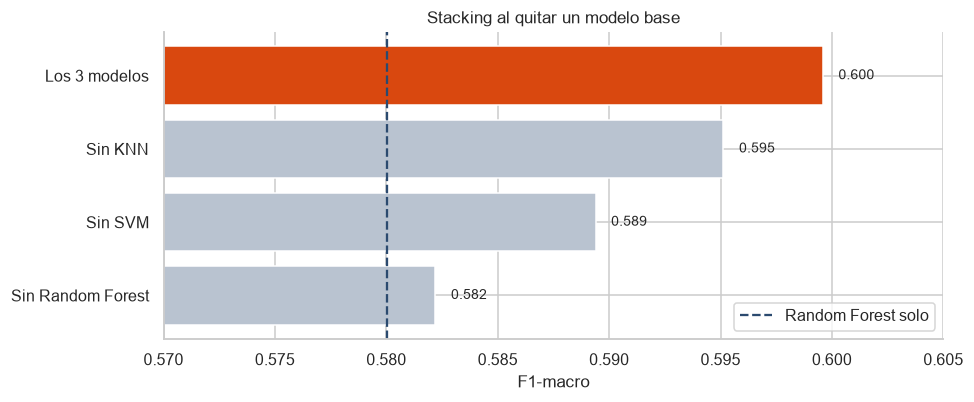

Los 3 modelos        0.5996
Sin KNN              0.5951
Sin SVM              0.5894
Sin Random Forest    0.5822
dtype: float64

In [11]:
# ============================================================
# 8 · ¿Qué pasa si quitamos un experto del stacking?
# ============================================================
ablacion = {'Los 3 modelos': tabla['Stacking']['F1-macro']}
for quitar in modelos_base:
    est = [(k, m) for k, m in modelos_base.items() if k != quitar]
    s = StackingClassifier(est, final_estimator=LogisticRegression(max_iter=2000), cv=cv, n_jobs=-1).fit(X_train, y_train)
    ablacion[f'Sin {quitar}'] = f1_score(y_test, s.predict(X_test), average='macro')
ablacion = pd.Series(ablacion)

fig, ax = plt.subplots(figsize=(9, 3.8))
cols = ['#D9480F'] + ['#B9C3D0'] * 3
barras = ax.barh(ablacion.index[::-1], ablacion.values[::-1], color=cols[::-1])
for b in barras:
    ax.text(b.get_width() + 0.0007, b.get_y() + b.get_height() / 2, f"{b.get_width():.3f}", va='center', fontsize=9)
ax.axvline(tabla['Random Forest']['F1-macro'], color='#2B4A6F', linestyle='--', label='Random Forest solo')
ax.set_xlim(0.57, 0.605); ax.set_xlabel('F1-macro'); ax.legend(loc='lower right')
ax.set_title('Stacking al quitar un modelo base')
plt.tight_layout(); plt.savefig('figuras/6_ablacion.png'); plt.show()
ablacion.round(4)

## Hallazgos

1. **El Stacking es nuestro mejor modelo hasta ahora:** F1 **0,600**, frente a 0,591 del Voting Soft y 0,580 de Random Forest solo. Mejora también el AUC (0,779) y baja los errores graves a **5,0%** (Random Forest: 6,1%).
2. **El juez aprendió a quién creerle:** confía sobre todo en Random Forest, luego en el SVM, y casi ignora a KNN para el nivel Intermedio. Es la "meritocracia" de la clase frente a la "democracia" del Voting.
3. **Los 3 expertos aportan**, aunque KNN sea el más débil: al quitarlo el F1 baja a 0,595; sin SVM, a 0,589; sin Random Forest, a **0,582**. La diversidad de familias es lo que da la ventaja.
4. **La validación cruzada no es opcional:** sin ella el juez confía en el modelo que memoriza (KNN) y el stacking queda **peor que un solo modelo** (F1 0,569).
5. **El meta-modelo simple basta:** cambiar el juez por otro más complejo no mejora el resultado.
6. **Donde más mejora es en los errores graves:** *Fácil → Difícil* baja de 48 (RF) a **42** y *Difícil → Fácil* de 62 a **48**. Para Yomi Level es lo más importante, porque es el error que hace que un principiante reciba algo que no puede entender.

## Conclusión

**Elegimos el Stacking (KNN + SVM + Random Forest, con Regresión Logística como juez)** como el modelo más preciso de Yomi Level: es el mejor en todas las métricas y el que menos confunde un título fácil con uno difícil.

**Limitaciones:**
- **La mejora es real pero moderada** (+2 puntos de F1 sobre Random Forest). El techo lo pone la información disponible: con 28 variables de ficha y conteos de palabras, el nivel **Intermedio** sigue siendo difícil de separar (F1 0,472).
- **Es más pesado:** entrena 3 modelos más 5 rondas de validación cruzada para el juez, y el SVM con probabilidades es lo más lento. Conviene en un servidor; para la app que corre en el navegador seguiríamos usando Random Forest solo.